## Install and import

In [1]:
import re, string, collections, time
import numpy as np
import pandas as pd
import torch
import matplotlib.pyplot as plt
from datasets import load_dataset
from transformers import AutoTokenizer, AutoModelForQuestionAnswering

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
N_EVAL = 1000
SEED = 42
print("Device:", DEVICE)

Device: cpu


## 1. Load the data and explore

In [2]:
squad = load_dataset("rajpurkar/squad")
print(squad)

train_df = squad["train"].to_pandas()
val_df = squad["validation"].to_pandas()


for df in (train_df, val_df):
    df["answer_texts"] = df["answers"].apply(lambda a: [str(t) for t in a["text"]])
    df["answer_start"] = df["answers"].apply(lambda a: int(a["answer_start"][0]))

val_df[["question", "answer_texts"]].head()

DatasetDict({
    train: Dataset({
        features: ['id', 'title', 'context', 'question', 'answers'],
        num_rows: 87599
    })
    validation: Dataset({
        features: ['id', 'title', 'context', 'question', 'answers'],
        num_rows: 10570
    })
})


,question,answer_texts
0,Which NFL team represented the AFC at Super Bo...,"[Denver Broncos, Denver Broncos, Denver Broncos]"
1,Which NFL team represented the NFC at Super Bo...,"[Carolina Panthers, Carolina Panthers, Carolin..."
2,Where did Super Bowl 50 take place?,"[Santa Clara, California, Levi's Stadium, Levi..."
3,Which NFL team won Super Bowl 50?,"[Denver Broncos, Denver Broncos, Denver Broncos]"
4,What color was used to emphasize the 50th anni...,"[gold, gold, gold]"


In [3]:
val_df["context_words"] = val_df["context"].str.split().str.len()
val_df["question_words"] = val_df["question"].str.split().str.len()
val_df["answer_words"] = val_df["answer_texts"].apply(lambda a: len(a[0].split()))

print("Unique passages (validation):", val_df["context"].nunique())
print(val_df[["context_words", "question_words", "answer_words"]].describe().round(1))

Unique passages (validation): 2067
       context_words  question_words  answer_words
count        10570.0         10570.0       10570.0
mean           124.0            10.2           3.0
std             56.1             3.6           3.0
min             22.0             3.0           1.0
25%             91.0             8.0           1.0
50%            112.0            10.0           2.0
75%            146.0            12.0           3.0
max            629.0            33.0          29.0


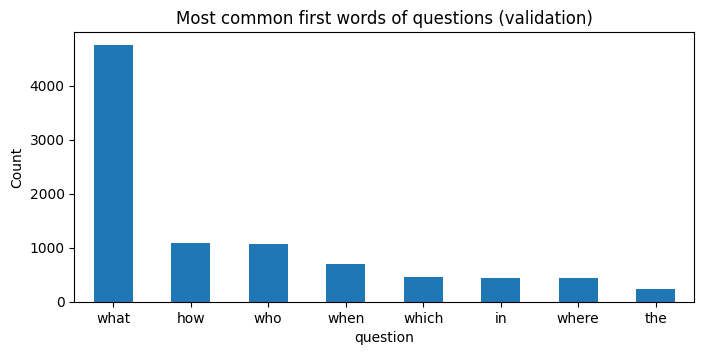

In [4]:
first_word = val_df["question"].str.split().str[0].str.lower()
top = first_word.value_counts().head(8)
top.plot.bar(figsize=(8, 3.5), title="Most common first words of questions (validation)")
plt.ylabel("Count"); plt.xticks(rotation=0); plt.show()

## 2. How a transformer reads a question and a passage


In [5]:
MODEL_NAME = "distilbert-base-cased-distilled-squad"
tokenizer = AutoTokenizer.from_pretrained(MODEL_NAME)

ex = val_df.iloc[0]
enc = tokenizer(ex.question, ex.context, truncation="only_second",
                max_length=384, return_offsets_mapping=True)

tokens = tokenizer.convert_ids_to_tokens(enc["input_ids"])
print("Question:", ex.question)
print("Number of tokens:", len(tokens))
print("First 25 tokens:", tokens[:25])
print("Special tokens:", tokenizer.cls_token, tokenizer.sep_token)

Question: Which NFL team represented the AFC at Super Bowl 50?
Number of tokens: 172
First 25 tokens: ['[CLS]', 'Which', 'NFL', 'team', 'represented', 'the', 'AFC', 'at', 'Super', 'Bowl', '50', '?', '[SEP]', 'Super', 'Bowl', '50', 'was', 'an', 'American', 'football', 'game', 'to', 'determine', 'the', 'champion']
Special tokens: [CLS] [SEP]


In [6]:
for tok_id, (s, e) in list(zip(enc["input_ids"], enc["offset_mapping"]))[40:50]:
    print(f"{tokenizer.convert_ids_to_tokens(tok_id):>12}  chars [{s}:{e}]  -> {ex.context[s:e]!r}" if e > s else
          f"{tokenizer.convert_ids_to_tokens(tok_id):>12}  (question / special token)")

    Football  chars [142:150]  -> 'Football'
  Conference  chars [151:161]  -> 'Conference'
           (  chars [162:163]  -> '('
         AFC  chars [163:166]  -> 'AFC'
           )  chars [166:167]  -> ')'
    champion  chars [168:176]  -> 'champion'
      Denver  chars [177:183]  -> 'Denver'
     Broncos  chars [184:191]  -> 'Broncos'
    defeated  chars [192:200]  -> 'defeated'
         the  chars [201:204]  -> 'the'


## 3. Span extraction from scratch



In [7]:
def load_qa(model_name):
    tok = AutoTokenizer.from_pretrained(model_name)
    mdl = AutoModelForQuestionAnswering.from_pretrained(model_name).to(DEVICE).eval()
    return tok, mdl


@torch.no_grad()
def answer_questions(questions, contexts, tokenizer, model, top_k=1, batch_size=16,
                     max_length=384, stride=128, max_answer_len=30, n_best=20):
    if isinstance(questions, str):
        questions, contexts = [questions], [contexts]

    all_results = []
    for b0 in range(0, len(questions), batch_size):
        qs, ctxs = questions[b0:b0 + batch_size], contexts[b0:b0 + batch_size]


        enc = tokenizer(qs, ctxs, truncation="only_second", max_length=max_length, stride=stride,
                        return_overflowing_tokens=True, return_offsets_mapping=True,
                        padding=True, return_tensors="pt")
        sample_map = enc["overflow_to_sample_mapping"].tolist()
        inputs = {k: v.to(DEVICE) for k, v in enc.items() if k in tokenizer.model_input_names}


        out = model(**inputs)
        start_all, end_all = out.start_logits.float().cpu(), out.end_logits.float().cpu()


        candidates = [[] for _ in qs]
        for w in range(len(sample_map)):
            seq_ids = enc.sequence_ids(w)
            offsets = enc["offset_mapping"][w].tolist()
            ctx_tokens = [t for t, s in enumerate(seq_ids) if s == 1]
            if not ctx_tokens:
                continue
            idx = torch.tensor(ctx_tokens)
            s_log, e_log = start_all[w][idx], end_all[w][idx]
            s_prob, e_prob = torch.softmax(s_log, -1), torch.softmax(e_log, -1)
            k = min(n_best, len(ctx_tokens))
            for a in torch.topk(s_log, k).indices.tolist():
                for e in torch.topk(e_log, k).indices.tolist():
                    if e < a or e - a + 1 > max_answer_len:
                        continue
                    char_start, char_end = offsets[ctx_tokens[a]][0], offsets[ctx_tokens[e]][1]
                    candidates[sample_map[w]].append((s_prob[a].item() * e_prob[e].item(), char_start, char_end))


        for j, cand in enumerate(candidates):
            cand.sort(reverse=True)
            results, seen = [], set()
            for score, cstart, cend in cand:
                if (cstart, cend) in seen:
                    continue
                seen.add((cstart, cend))
                results.append({"answer": ctxs[j][cstart:cend], "score": score, "start": cstart, "end": cend})
                if len(results) == top_k:
                    break
            all_results.append(results or [{"answer": "", "score": 0.0, "start": 0, "end": 0}])
    return all_results


tokenizer, model = load_qa(MODEL_NAME)
for i in range(3):
    r = val_df.iloc[i]
    best = answer_questions(r.question, r.context, tokenizer, model)[0][0]
    print(f"Q: {r.question}\n   predicted: {best['answer']!r}  | gold: {r.answer_texts[0]!r}  | confidence={best['score']:.2f}\n")

Loading weights:   0%|          | 0/102 [00:00<?, ?it/s]

Q: Which NFL team represented the AFC at Super Bowl 50?
   predicted: 'Denver Broncos'  | gold: 'Denver Broncos'  | confidence=0.62

Q: Which NFL team represented the NFC at Super Bowl 50?
   predicted: 'Carolina Panthers'  | gold: 'Carolina Panthers'  | confidence=0.80

Q: Where did Super Bowl 50 take place?
   predicted: "Levi's Stadium in the San Francisco Bay Area at Santa Clara, California"  | gold: 'Santa Clara, California'  | confidence=0.34



## 4. Evaluation

In [8]:
def normalize_answer(s):
    s = s.lower()
    s = "".join(ch for ch in s if ch not in set(string.punctuation))
    s = re.sub(r"\b(a|an|the)\b", " ", s)
    return " ".join(s.split())

def exact_match(pred, gold):
    return float(normalize_answer(pred) == normalize_answer(gold))

def f1_score(pred, gold):
    p, g = normalize_answer(pred).split(), normalize_answer(gold).split()
    common = collections.Counter(p) & collections.Counter(g)
    n_same = sum(common.values())
    if len(p) == 0 or len(g) == 0:
        return float(p == g)
    if n_same == 0:
        return 0.0
    precision, recall = n_same / len(p), n_same / len(g)
    return 2 * precision * recall / (precision + recall)

def best_over_refs(metric, pred, refs):
    return max(metric(pred, g) for g in refs)

# Quick sanity checks
assert best_over_refs(exact_match, "The Eiffel Tower", ["eiffel tower"]) == 1.0
assert best_over_refs(f1_score, "in Paris, France", ["Paris"]) == 0.5
assert best_over_refs(exact_match, "London", ["Paris"]) == 0.0
print("Metric checks passed")

Metric checks passed


## 5. Evaluate

In [9]:
eval_df = val_df.sample(n=min(N_EVAL, len(val_df)), random_state=SEED).reset_index(drop=True)

def evaluate_model(model_name, df=eval_df, batch_size=16):
    tok, mdl = load_qa(model_name)
    t0 = time.time()
    outputs = answer_questions(df["question"].tolist(), df["context"].tolist(), tok, mdl,
                               top_k=1, batch_size=batch_size)
    seconds = time.time() - t0
    outputs = [o[0] for o in outputs]

    per_example = df[["question", "context", "answer_texts"]].copy()
    per_example["prediction"] = [o["answer"] for o in outputs]
    per_example["score"] = [o["score"] for o in outputs]
    per_example["em"] = [best_over_refs(exact_match, p, r) for p, r in zip(per_example.prediction, per_example.answer_texts)]
    per_example["f1"] = [best_over_refs(f1_score, p, r) for p, r in zip(per_example.prediction, per_example.answer_texts)]

    summary = {
        "model": model_name,
        "EM": round(100 * per_example["em"].mean(), 2),
        "F1": round(100 * per_example["f1"].mean(), 2),
        "params (M)": round(sum(p.numel() for p in mdl.parameters()) / 1e6, 1),
        "sec / question": round(seconds / len(df), 3),
    }
    del mdl, tok
    if torch.cuda.is_available():
        torch.cuda.empty_cache()
    return summary, per_example

summary, per_example = evaluate_model(MODEL_NAME)
print(summary)
per_example[["question", "prediction", "answer_texts", "em", "f1"]].head(10)

Loading weights:   0%|          | 0/102 [00:00<?, ?it/s]

{'model': 'distilbert-base-cased-distilled-squad', 'EM': np.float64(78.4), 'F1': np.float64(86.42), 'params (M)': 65.2, 'sec / question': 0.756}


,question,prediction,answer_texts,em,f1
0,What does increased oxygen concentrations in t...,carbon monoxide from the heme group of hemoglobin,"[carbon monoxide, carbon monoxide, carbon mono...",0.0,0.444444
1,Does the new deal include Video on demand and ...,Currently there is no indication,"[no, no indication, no indication]",0.0,0.571429
2,In which year did Genghis Khan's grandson inva...,1237,"[1237, 1237, 1237]",1.0,1.000000
3,Where is the Hyde Park Day School located?,University of Chicago campus,"[the University of Chicago campus, University ...",1.0,1.000000
4,What does the WG I Summary for Policymakers re...,increasing the atmospheric concentrations,[substantially increasing the atmospheric conc...,0.0,0.857143
5,For how many years was evidence shown that hum...,"11,000","[11,000 years, at least 11,000 years, at least...",0.0,0.666667
6,Who lost to the Broncos in the divisional round?,Pittsburgh Steelers,"[Pittsburgh Steelers, the Pittsburgh Steelers,...",1.0,1.000000
7,Who was hired to be the deputy director of the...,Joseph Shea,"[Joseph Shea, Joseph Shea,, Joseph Shea,, Jose...",1.0,1.000000
8,What register did Chris Keates think that some...,sex offenders register,"[the sex offenders register, sex offenders, se...",1.0,1.000000
9,What did Luther say would allow the Jews to stay?,Christian love toward them and pray that they ...,"[that they convert, became Christians, convert]",0.0,0.500000


## 6. Bonus:

In [10]:
MODELS = {
    "DistilBERT": "distilbert-base-cased-distilled-squad",
    "BERT":       "csarron/bert-base-uncased-squad-v1",
    "RoBERTa":    "csarron/roberta-base-squad-v1",
    "ALBERT":     "twmkn9/albert-base-v2-squad2",
}

all_summaries, all_examples = [], {}
for family, name in MODELS.items():
    print(f"Evaluating {family}: {name}")
    try:
        s, ex_df = evaluate_model(name)
        s["family"] = family
        all_summaries.append(s)
        all_examples[family] = ex_df
        print("   ", {k: s[k] for k in ("EM", "F1", "sec / question")})
    except Exception as e:
        print(f"    skipped ({type(e).__name__}: {str(e)[:100]})")

comparison = pd.DataFrame(all_summaries).set_index("family")[["model", "EM", "F1", "params (M)", "sec / question"]]
comparison

Evaluating DistilBERT: distilbert-base-cased-distilled-squad


Loading weights:   0%|          | 0/102 [00:00<?, ?it/s]

    {'EM': np.float64(78.4), 'F1': np.float64(86.42), 'sec / question': 0.684}
Evaluating BERT: csarron/bert-base-uncased-squad-v1


Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] BertForQuestionAnswering LOAD REPORT from: csarron/bert-base-uncased-squad-v1
Key                      | Status     |  | 
-------------------------+------------+--+-
bert.pooler.dense.weight | UNEXPECTED |  | 
bert.pooler.dense.bias   | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


...

[transformers] AlbertForQuestionAnswering LOAD REPORT from: twmkn9/albert-base-v2-squad2
Key                  | Status     |  | 
---------------------+------------+--+-
albert.pooler.bias   | UNEXPECTED |  | 
albert.pooler.weight | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


model.safetensors: reconstructing file:   0%|          |  0.00B / 46.7MB            

model.safetensors: downloading bytes:           |  0.00B            

    {'EM': np.float64(42.7), 'F1': np.float64(54.14), 'sec / question': 1.677}


,model,EM,F1,params (M),sec / question
family,,,,,
DistilBERT,distilbert-base-cased-distilled-squad,78.4,86.42,65.2,0.684
BERT,csarron/bert-base-uncased-squad-v1,79.9,87.18,108.9,1.322
RoBERTa,csarron/roberta-base-squad-v1,81.2,88.65,124.1,1.313
ALBERT,twmkn9/albert-base-v2-squad2,42.7,54.14,11.1,1.677


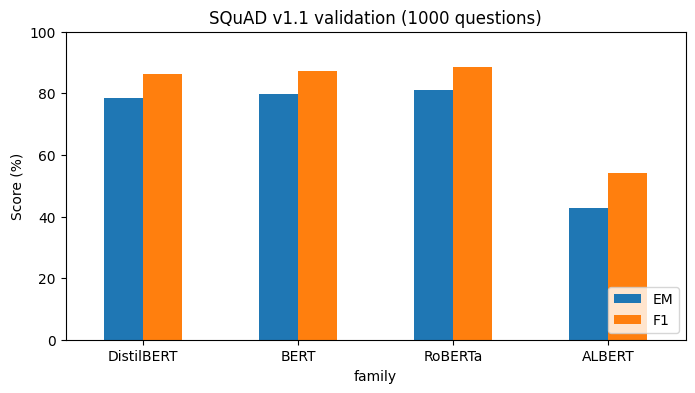

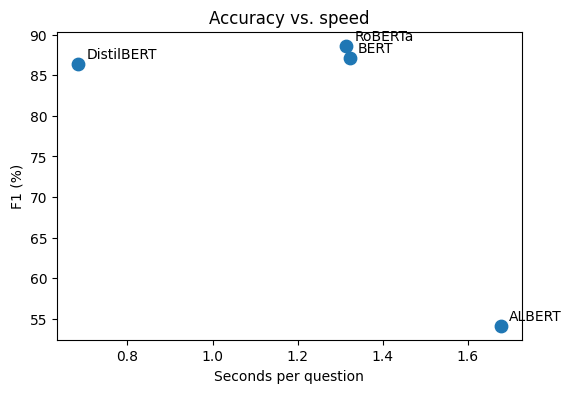

In [11]:
comparison[["EM", "F1"]].plot.bar(figsize=(8, 4), ylim=(0, 100),
                                  title=f"SQuAD v1.1 validation ({len(eval_df)} questions)")
plt.ylabel("Score (%)"); plt.xticks(rotation=0); plt.legend(loc="lower right"); plt.show()

# Accuracy vs speed
fig, ax = plt.subplots(figsize=(6, 4))
ax.scatter(comparison["sec / question"], comparison["F1"], s=80)
for fam, row in comparison.iterrows():
    ax.annotate(fam, (row["sec / question"], row["F1"]), textcoords="offset points", xytext=(6, 4))
ax.set_xlabel("Seconds per question"); ax.set_ylabel("F1 (%)"); ax.set_title("Accuracy vs. speed")
plt.show()

## 7. Error analysis


In [12]:
best_family = comparison["F1"].idxmax()
errors = all_examples[best_family]
print("Best model:", best_family)
print(f"Exact match: {errors.em.mean():.1%} | partially correct (0 < F1 < 1): "
      f"{((errors.f1 > 0) & (errors.f1 < 1)).mean():.1%} | completely wrong (F1 = 0): {(errors.f1 == 0).mean():.1%}")

errors[errors.f1 == 0][["question", "prediction", "answer_texts"]].head(8)

Best model: RoBERTa
Exact match: 81.2% | partially correct (0 < F1 < 1): 12.7% | completely wrong (F1 = 0): 6.1%


,question,prediction,answer_texts
37,"What was Isiah Bowman nick name, as known by t...","American Empire,","[Wilson's geographer, Wilson's geographer, Wil..."
38,Which Super Bowl halftime show did Beyoncé hea...,Coldplay,"[Super Bowl XLVII, Super Bowl XLVII, Super Bow..."
50,"What is a genuine love of God with heart, soul...",Sanctifying Grace,"[Christian Perfection, Christian Perfection, C..."
58,The Ottoman empire controlled territory on thr...,the Horn of Africa.,"[Europe, Europe, Europe, Europe, Europe]"
60,Who was the #2 pick in the 2011 NFL Draft?,Newton,"[Von Miller, Von Miller, Miller]"
87,Other theories of the word's origin can be gen...,"""Hugues hypothesis""",[double or triple non-French linguistic origin...
117,Which English sculptor who became the leading ...,"Nicholas Stone,","[Sir Francis Chantrey, Sir Francis Chantrey,, ..."
144,What choice did French have for surrendering l...,"cede the former,",[continental North American possessions east o...


In [13]:
wrong = pd.DataFrame({fam: (d.f1 == 0) for fam, d in all_examples.items()})
print("Wrong in ALL models:", wrong.all(axis=1).sum(), "of", len(wrong))
print("Wrong in at least one model:", wrong.any(axis=1).sum())

errors = errors.assign(qtype=errors["question"].str.split().str[0].str.lower())
by_type = errors.groupby("qtype").agg(n=("f1", "size"), EM=("em", "mean"), F1=("f1", "mean"))
by_type[by_type.n >= 20].sort_values("F1", ascending=False).round(3)

Wrong in ALL models: 17 of 1000
Wrong in at least one model: 371


,n,EM,F1
qtype,,,
when,68,0.941,0.970
who,107,0.907,0.933
where,49,0.857,0.933
in,35,0.857,0.891
how,81,0.802,0.885
what,454,0.784,0.871
which,46,0.804,0.858


## 8. Try it on your own text

The same function is used by the Streamlit app (`app.py`).

In [14]:
best_tok, best_model = load_qa(MODELS.get(best_family, MODEL_NAME))

passage = """The Nile is a major north-flowing river in northeastern Africa. It flows into the
Mediterranean Sea and is about 6,650 km long. The Nile has two major tributaries,
the White Nile and the Blue Nile, which meet in Khartoum, the capital of Sudan."""

for q in ["How long is the Nile?", "Where do the White Nile and the Blue Nile meet?",
          "Which sea does the Nile flow into?"]:
    r = answer_questions(q, passage, best_tok, best_model)[0][0]
    print(f"Q: {q}\nA: {r['answer']}  (confidence {r['score']:.2f})\n")

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] RobertaForQuestionAnswering LOAD REPORT from: csarron/roberta-base-squad-v1
Key                         | Status     |  | 
----------------------------+------------+--+-
roberta.pooler.dense.weight | UNEXPECTED |  | 
roberta.pooler.dense.bias   | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


Q: How long is the Nile?
A: 6,650 km long.  (confidence 0.24)

Q: Where do the White Nile and the Blue Nile meet?
A: Khartoum  (confidence 0.74)

Q: Which sea does the Nile flow into?
A: Mediterranean Sea  (confidence 0.58)

